# Pilot ligands docked onto their holo ensembles of a-syn-C-term with AutoDock Vina-GPU

Populations of intermolecular interactions and dual residue contact probability for the same 10 pilot ligands, each docked onto 5,000 bound frames of its own MD simulation with a-syn-C-term (minimum protein-ligand heavy-atom distance < 6 A) -- holo docking. Box geometry as in the apo job.

Receptors are the all-atom PDB frames. The PDBQT receptors used for docking have all but ~29 polar hydrogens stripped, which under-counts H-bonds about threefold, so they are not used here.

Each frame is the receptor conformation that was docked against, plus the best-of-20
pose (the lowest-scoring of the 20 per-residue boxes). The example notebook reweights
t-SNE clusters by their MD populations; these ensembles are instead stride-sampled from
equilibrium trajectories, so every frame carries equal weight and the ensemble is treated
as a single cluster with weight 1.

Build the input once with
`python build_docked_trajectories.py --job holo_pilot10`.

In [1]:
import os, sys, json
import numpy as np
import mdtraj as md

for p in ("~/data/scripts", "~/data/scripts/docking_analysis"):
    p = os.path.expanduser(p)
    if os.path.isdir(os.path.join(p, "docking_tools")) and p not in sys.path:
        sys.path.insert(0, p)
from docking_tools import trajectory_analysis
from docking_tools import plotting

In [2]:
JOB = "holo_pilot10"
DATA = os.path.expanduser(f"~/data/docked_trajectories/{JOB}")
LIGANDS = [38, 5, 28, 34, 3, 24, 17, 53, 9, 40]
PIPELINE = os.path.expanduser("~/data/VinaGPU/hpc_results/holo_08192026/analysis_v2")

# one cluster with weight 1 (uniform, stride-sampled ensemble)
N_CLUS = 1
weights = np.array([1.0])
contacts = {}

In [3]:
def load_docked(lig):
    """Docked trajectory + ligand atom groups written by build_docked_trajectories.py."""
    top = md.load_topology(os.path.join(DATA, f"lig{lig}_top.pdb"))
    traj = md.Trajectory(np.load(os.path.join(DATA, f"lig{lig}_xyz.npy")), top)
    with open(os.path.join(DATA, f"lig{lig}_groups.json")) as fh:
        groups = json.load(fh)
    return traj, groups


def analyse(lig):
    traj, g = load_docked(lig)
    n_frames = traj.n_frames
    # number of residues in the protein; the ligand is the last residue (0 indexed)
    n_res = traj.atom_slice(traj.top.select('protein')).n_residues
    ligand_idx = n_res
    shape = (N_CLUS, n_frames, n_res)
    empty = lambda: np.zeros(shape)

    contacts = {}
    contacts['hphob'] = trajectory_analysis.hphob_contacts(traj, ligand_idx).reshape(shape)
    contacts['aro'] = (trajectory_analysis.aro_contacts(traj, ligand_rings=g['aromatic_rings']).reshape(shape)
                       if g['aromatic_rings'] else empty())
    contacts['hbond'] = (trajectory_analysis.hbond(traj, ligand_idx, lig_hbond_donors=g['hbond_donors']).reshape(shape)
                         if g['hbond_donors'] else empty())
    contacts['charge'] = (trajectory_analysis.charge_contacts(traj, Ligand_Pos_Charges=g['positive_charges']).reshape(shape)
                          if g['positive_charges'] else empty())
    contacts['dual'] = np.array([trajectory_analysis.dual_contact(traj, residue_idx=ligand_idx)])
    print(f"ligand {lig}: {n_frames} frames, {n_res} residues")
    return contacts

## Ligand atom groups

In [4]:
# detected ligand atom groups -- check these against each ligand's chemistry
# before reading the aromatic, H-bond and charge panels
for lig in LIGANDS:
    try:
        with open(os.path.join(DATA, f"lig{lig}_groups.json")) as fh:
            g = json.load(fh)
    except FileNotFoundError:
        print(f"ligand {lig:>3}: not built yet"); continue
    print(f"ligand {lig:>3}: {g['n_frames']:>6} frames | rings {len(g['aromatic_rings'])} "
          f"| donors {len(g['hbond_donors'])} | cation {g['positive_charges']} "
          f"| anion {g['negative_charges']}")

ligand  38:   5000 frames | rings 1 | donors 2 | cation [300] | anion []
ligand   5:   5000 frames | rings 1 | donors 2 | cation [300] | anion []
ligand  28:   5000 frames | rings 2 | donors 2 | cation [310] | anion []
ligand  34:   5000 frames | rings 2 | donors 2 | cation [310] | anion []
ligand   3:   5000 frames | rings 2 | donors 2 | cation [310] | anion []
ligand  24:   5000 frames | rings 2 | donors 3 | cation [314] | anion []
ligand  17:   5000 frames | rings 2 | donors 2 | cation [300] | anion []
ligand  53:   5000 frames | rings 1 | donors 2 | cation [306] | anion []
ligand   9:   5000 frames | rings 2 | donors 2 | cation [306] | anion []
ligand  40:   5000 frames | rings 2 | donors 3 | cation [316] | anion []


## Ligand 38

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 38: 5000 frames, 20 residues


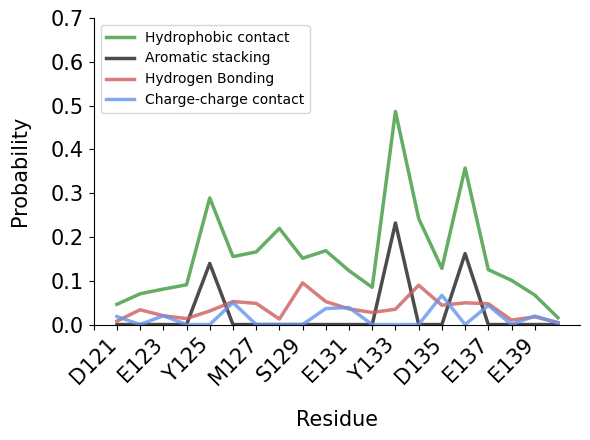

In [5]:
contacts[38] = analyse(38)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[38], weights)

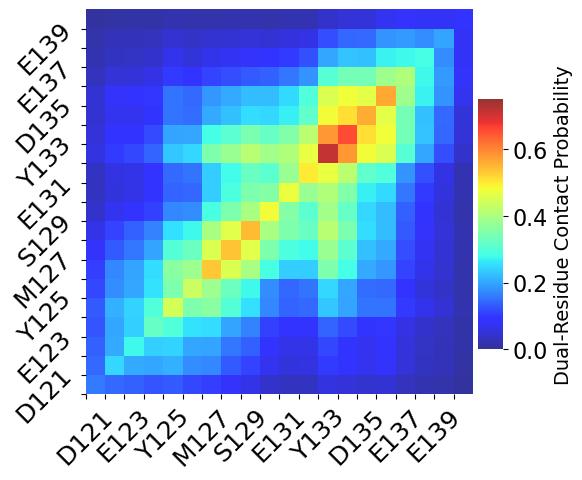

In [6]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[38]['dual'], weights)

## Ligand 5

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 5: 5000 frames, 20 residues


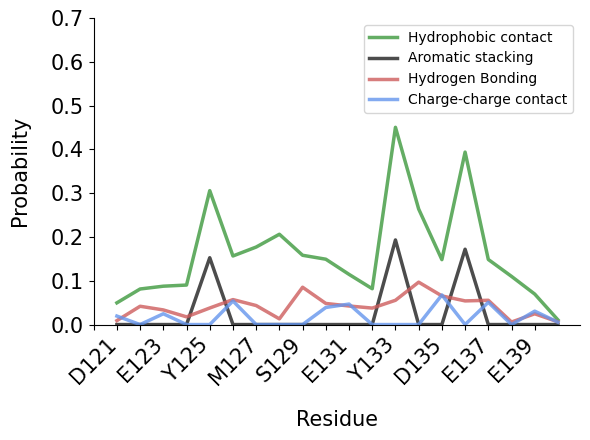

In [7]:
contacts[5] = analyse(5)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[5], weights)

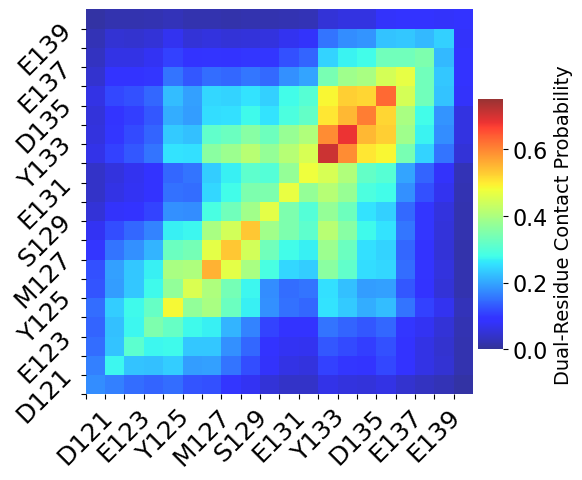

In [8]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[5]['dual'], weights)

## Ligand 28

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 28: 5000 frames, 20 residues


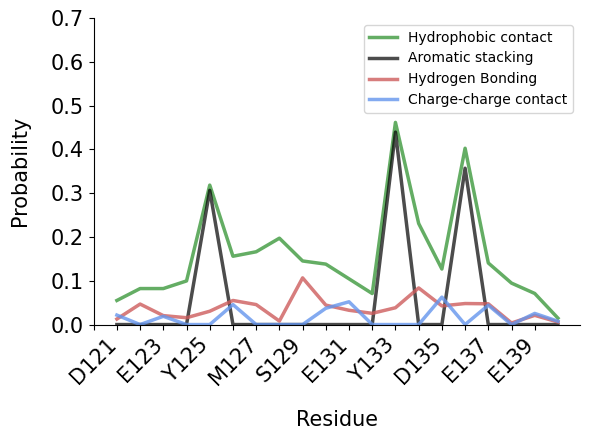

In [9]:
contacts[28] = analyse(28)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[28], weights)

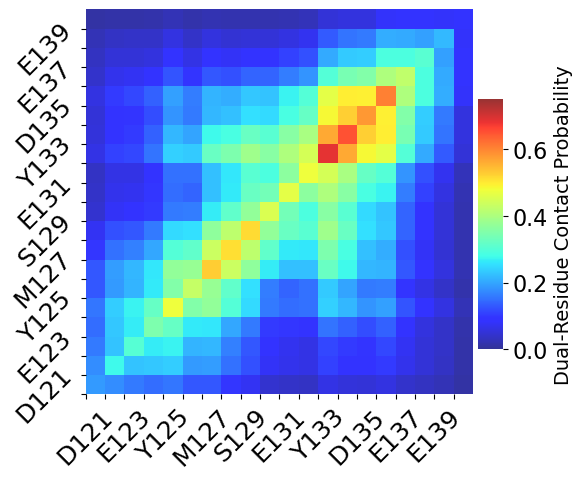

In [10]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[28]['dual'], weights)

## Ligand 34

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 34: 5000 frames, 20 residues


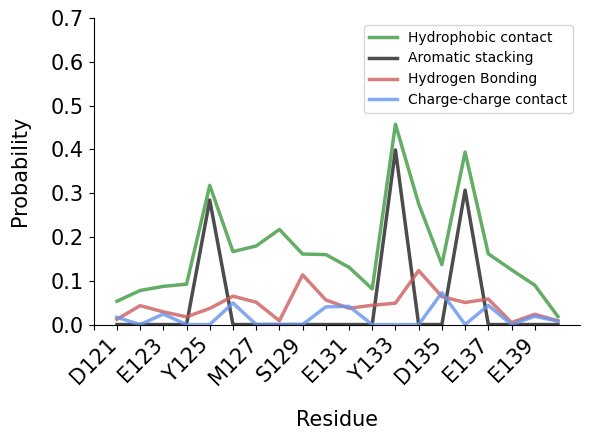

In [11]:
contacts[34] = analyse(34)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[34], weights)

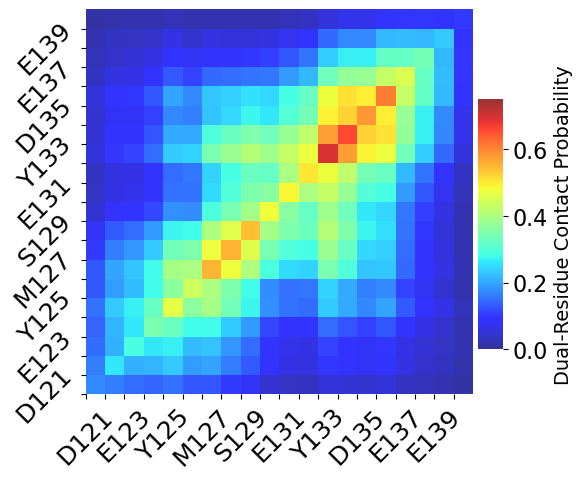

In [12]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[34]['dual'], weights)

## Ligand 3

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 3: 5000 frames, 20 residues


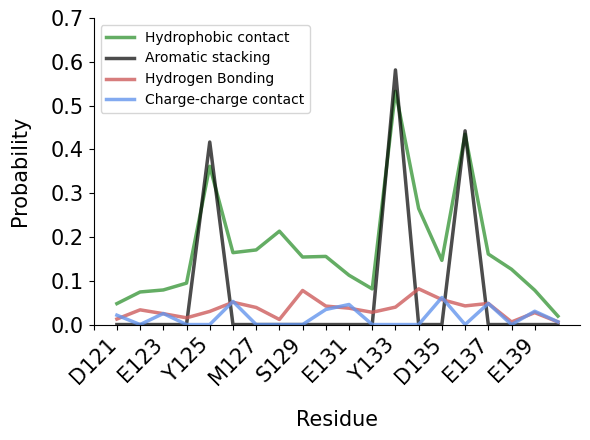

In [13]:
contacts[3] = analyse(3)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[3], weights)

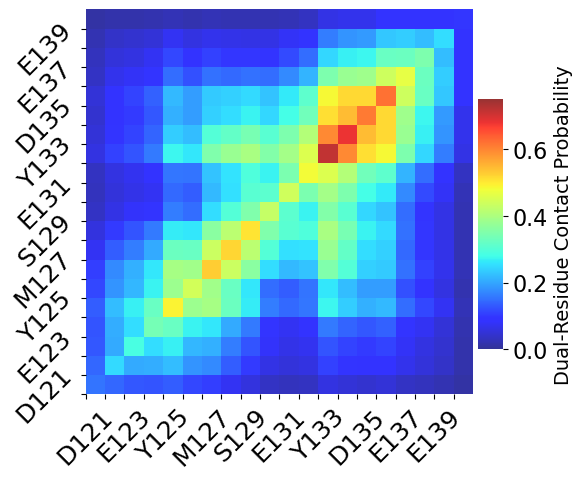

In [14]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[3]['dual'], weights)

## Ligand 24

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 24: 5000 frames, 20 residues


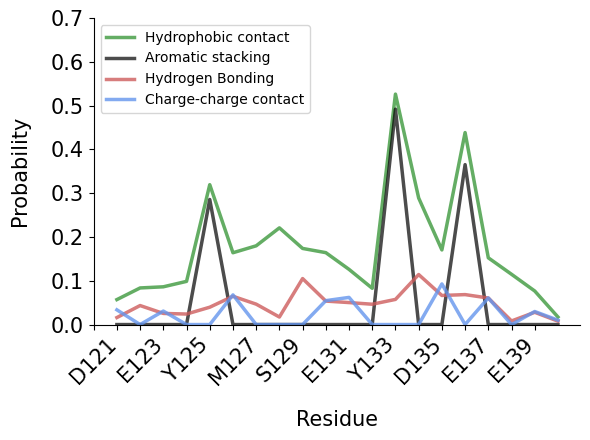

In [15]:
contacts[24] = analyse(24)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[24], weights)

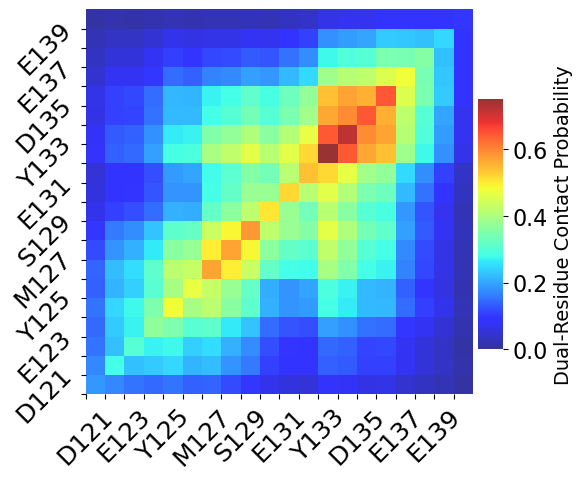

In [16]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[24]['dual'], weights)

## Ligand 17

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 17: 5000 frames, 20 residues


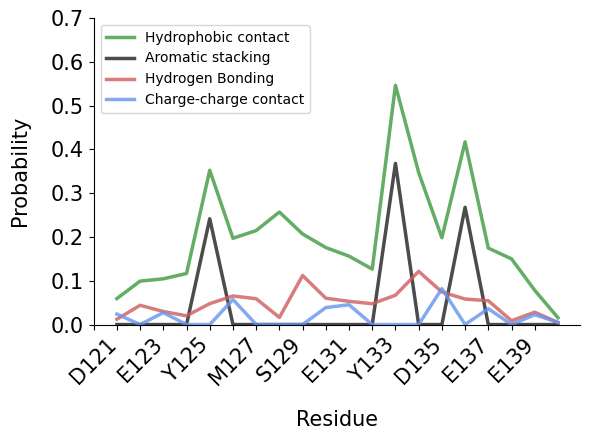

In [17]:
contacts[17] = analyse(17)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[17], weights)

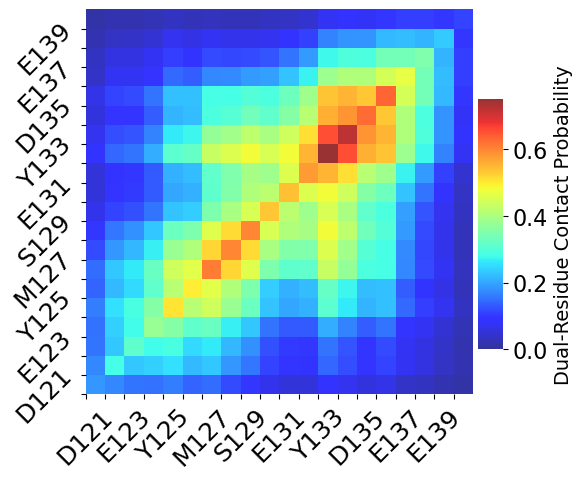

In [18]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[17]['dual'], weights)

## Ligand 53

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 53: 5000 frames, 20 residues


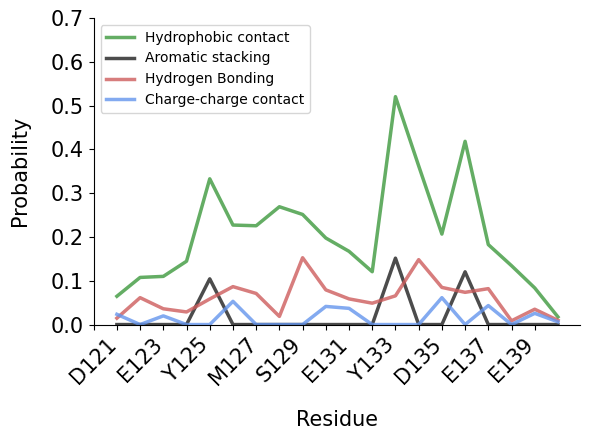

In [19]:
contacts[53] = analyse(53)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[53], weights)

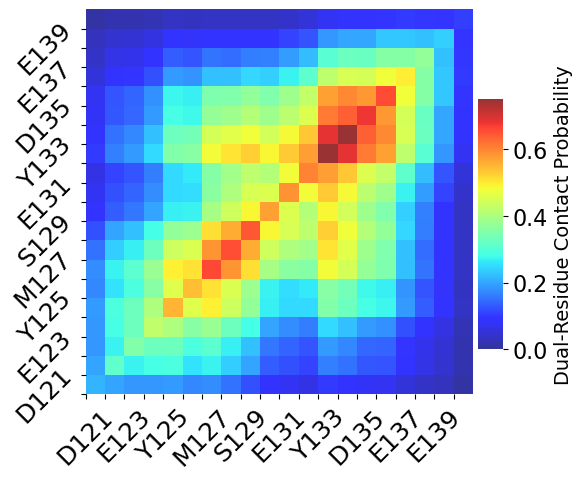

In [20]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[53]['dual'], weights)

## Ligand 9

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 9: 5000 frames, 20 residues


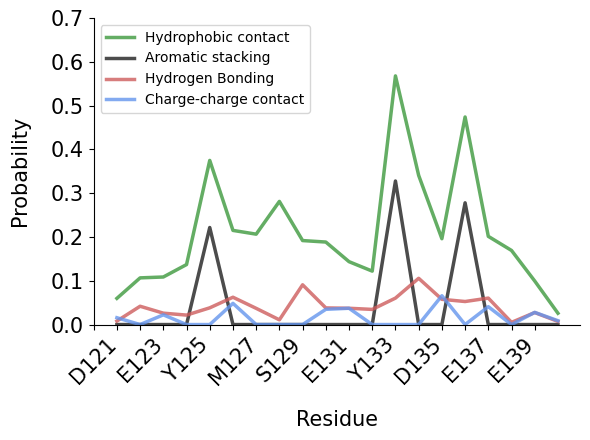

In [21]:
contacts[9] = analyse(9)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[9], weights)

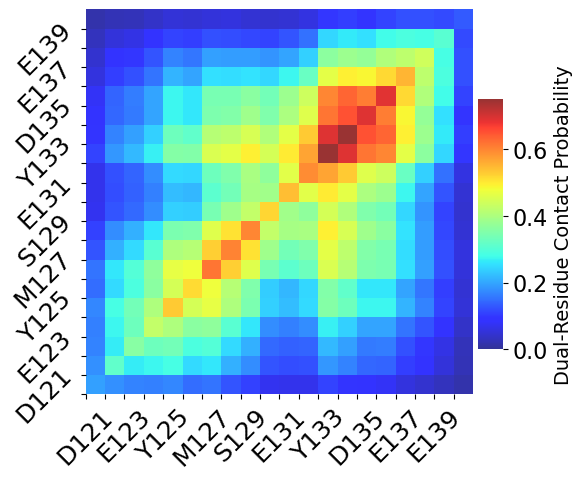

In [22]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[9]['dual'], weights)

## Ligand 40

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 40: 5000 frames, 20 residues


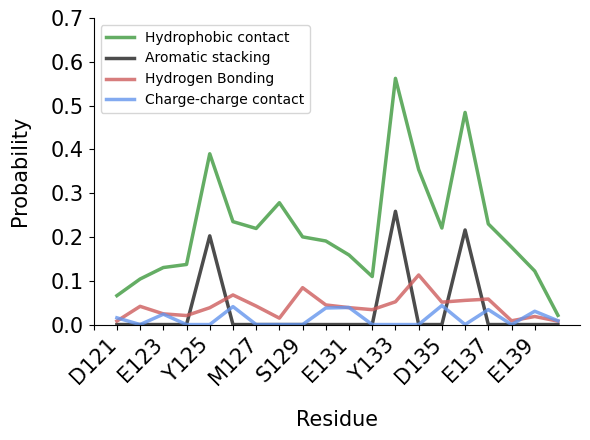

In [23]:
contacts[40] = analyse(40)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[40], weights)

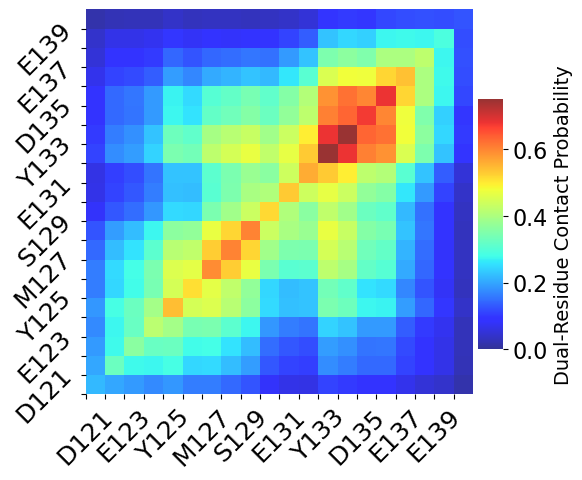

In [24]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[40]['dual'], weights)

## Consistency check against the batch-pipeline fingerprints

In [25]:
# The same fingerprints were computed earlier by the batch pipeline; per-residue
# profiles from this notebook should agree with them closely.
for lig in LIGANDS:
    p = os.path.join(PIPELINE, f"lig{lig}_fingerprint.npz")
    if lig not in contacts or not os.path.exists(p):
        continue
    old = np.load(p, allow_pickle=True)
    row = []
    for key in ('hphob', 'aro', 'hbond', 'charge'):
        if key not in old.files:
            row.append(f"{key} -"); continue
        a = np.asarray(old[key], float)
        a = a.mean(axis=0) if a.ndim == 2 else a
        b = contacts[lig][key][0].mean(axis=0)
        n = min(a.size, b.size)
        r = np.corrcoef(a[:n], b[:n])[0, 1] if a[:n].std() > 0 and b[:n].std() > 0 else float('nan')
        row.append(f"{key} r={r:.3f}")
    print(f"ligand {lig:>3}: " + "  ".join(row))

ligand  38: hphob r=1.000  aro r=1.000  hbond r=1.000  charge r=1.000
ligand   5: hphob r=1.000  aro r=1.000  hbond r=1.000  charge r=1.000
ligand  28: hphob r=1.000  aro r=1.000  hbond r=1.000  charge r=1.000
ligand  34: hphob r=1.000  aro r=1.000  hbond r=1.000  charge r=1.000
ligand   3: hphob r=1.000  aro r=1.000  hbond r=1.000  charge r=1.000
ligand  24: hphob r=1.000  aro r=1.000  hbond r=1.000  charge r=1.000
ligand  17: hphob r=1.000  aro r=1.000  hbond r=1.000  charge r=1.000
ligand  53: hphob r=1.000  aro r=1.000  hbond r=1.000  charge r=1.000
ligand   9: hphob r=1.000  aro r=1.000  hbond r=1.000  charge r=1.000


ligand  40: hphob r=1.000  aro r=1.000  hbond r=1.000  charge r=0.973
